Линейная регрессия: MSE = 0.1299, R2 = 0.9604
Полиномиальная регрессия:
  Степень 1: Train R2 = 0.9700, Test R2 = 0.9604
  Степень 2: Train R2 = 0.9755, Test R2 = 0.9713
  Степень 3: Train R2 = 0.9846, Test R2 = 0.9684
  Степень 4: Train R2 = 0.9859, Test R2 = 0.9188
  Степень 5: Train R2 = 0.9862, Test R2 = 0.9121
  Степень 6: Train R2 = 0.9864, Test R2 = 0.9004
  Степень 7: Train R2 = 0.9864, Test R2 = 0.9025
  Степень 8: Train R2 = 0.9858, Test R2 = 0.8551
  Степень 9: Train R2 = 0.9854, Test R2 = 0.8112
  Степень 10: Train R2 = 0.9848, Test R2 = 0.6510



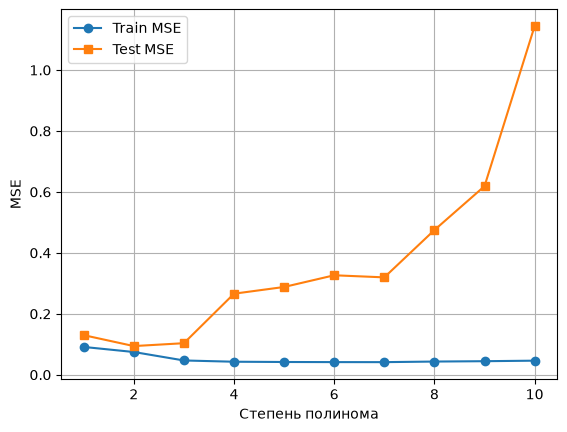

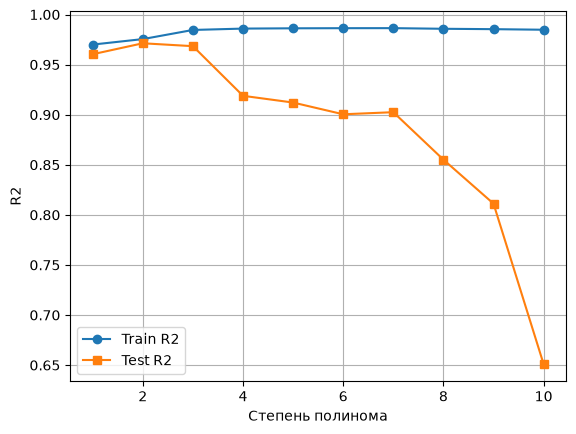

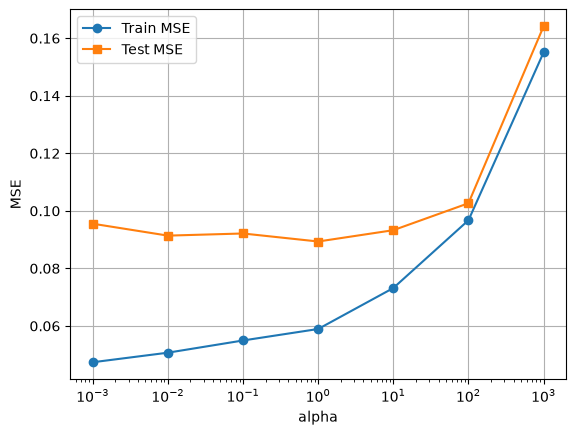

Лучший результат Ridge: Test R2 = 0.9727 при alpha=1


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# 1. Данные и ручное разделение
cols = ['sl', 'sw', 'pl', 'pw', 'cls']
df = pd.read_csv('iris.data', names=cols).drop('cls', axis=1)

np.random.seed(42)
idx = np.random.permutation(len(df))
test_idx, train_idx = idx[:30], idx[30:] # 30 на тест, 120 на обучение

X_train, y_train = df.iloc[train_idx].drop('pl', axis=1).values, df.iloc[train_idx]['pl'].values
X_test, y_test = df.iloc[test_idx].drop('pl', axis=1).values, df.iloc[test_idx]['pl'].values

# 2. Обычная линейная регрессия
lin = LinearRegression().fit(X_train, y_train)
pred_lin = lin.predict(X_test)
print(f"Линейная регрессия: MSE = {mean_squared_error(y_test, pred_lin):.4f}, R2 = {r2_score(y_test, pred_lin):.4f}")

# 3. Полиномиальная регрессия
train_err, test_err = [], []
train_r2, test_r2 = [], []

for d in range(1, 11):
    poly = PolynomialFeatures(d)
    Xtr, Xte = poly.fit_transform(X_train), poly.transform(X_test)
    m = LinearRegression().fit(Xtr, y_train)
    
    p_tr, p_te = m.predict(Xtr), m.predict(Xte)
    
    train_err.append(mean_squared_error(y_train, p_tr))
    test_err.append(mean_squared_error(y_test, p_te))
    train_r2.append(r2_score(y_train, p_tr))
    test_r2.append(r2_score(y_test, p_te))

# R2 для полиномов
print("Полиномиальная регрессия:")
for d in range(1, 11):
    print(f"  Степень {d}: Train R2 = {train_r2[d-1]:.4f}, Test R2 = {test_r2[d-1]:.4f}")
print()

# Графики для полиномов
plt.plot(range(1, 11), train_err, label='Train MSE', marker='o')
plt.plot(range(1, 11), test_err, label='Test MSE', marker='s')
plt.xlabel('Степень полинома'); plt.ylabel('MSE'); plt.legend(); plt.grid(); plt.show()

# Второй график для R2
plt.plot(range(1, 11), train_r2, label='Train R2', marker='o')
plt.plot(range(1, 11), test_r2, label='Test R2', marker='s')
plt.xlabel('Степень полинома'); plt.ylabel('R2'); plt.legend(); plt.grid(); plt.show()

# 4. Регуляризация (Ridge) на полиноме 3-й степени
poly = PolynomialFeatures(3)
Xtr, Xte = poly.fit_transform(X_train), poly.transform(X_test)
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_r, test_r = [], []
train_r2_r, test_r2_r = [], []

for a in alphas:
    r = Ridge(alpha=a).fit(Xtr, y_train)
    p_tr, p_te = r.predict(Xtr), r.predict(Xte)
    
    train_r.append(mean_squared_error(y_train, p_tr))
    test_r.append(mean_squared_error(y_test, p_te))
    train_r2_r.append(r2_score(y_train, p_tr))
    test_r2_r.append(r2_score(y_test, p_te))

plt.plot(alphas, train_r, label='Train MSE', marker='o')
plt.plot(alphas, test_r, label='Test MSE', marker='s')
plt.xscale('log'); plt.xlabel('alpha'); plt.ylabel('MSE'); plt.legend(); plt.grid(); plt.show()

# Вывод лучшего R2 и alpha
best_idx = np.argmax(test_r2_r)
print(f"Лучший результат Ridge: Test R2 = {test_r2_r[best_idx]:.4f} при alpha={alphas[best_idx]}")